In [2]:
# @title 0. 공통 준비 (모든 노트북 동일)
import sys
if any(m.startswith("msrs_paper") for m in sys.modules):
    raise RuntimeError("이전에 불러온 코드가 메모리에 남아 있습니다. 메뉴 '런타임 → 세션 다시 시작' 후 이 셀부터 다시 실행하세요.")
from google.colab import drive
drive.mount("/content/drive", force_remount=True)

REPO_URL = "https://github.com/yuhwani/multimodal-recsys.git"  # upstream에 머지되면 3sunghynix 주소로 변경
BRANCH = "main"
!rm -rf /content/repo && git clone -q -b {BRANCH} {REPO_URL} /content/repo
!pip -q install -r /content/repo/paper/requirements.txt
!cd /content/repo && git log -1 --format="코드 커밋: %h %s (%cd)"

import sys
sys.path.insert(0, "/content/repo/paper")
from msrs_paper.config import load_all, Paths
cfg, exps, plan = load_all()
DRIVE_ROOT = "/content/drive/MyDrive/msrs_paper (1)"  # 공유 폴더 바로가기 경로가 다르면 이 줄만 바꾼다
paths = Paths(DRIVE_ROOT).make_dirs()
print("드라이브 폴더:", paths.root)
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 83.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 4.3 MB/s eta 0:00:00
코드 커밋: 20c4ff4 docs: record 7th pre-registration results (H14 UME +0.021 supported; H12, H13 not supported) (Mon Oct 19 14:39:01 2026 +0900)
드라이브 폴더: /content/drive/MyDrive/msrs_paper (1)
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [3]:
# @title 1. 공유 준비물 확인 (체크섬이 다르면 멈춤)
from msrs_paper.utils import verify_manifest
m = verify_manifest(paths)
print(f"준비물 {len(m['files'])}개 일치 — 준비물 커밋 {m['git_commit']}")

준비물 35개 일치 — 준비물 커밋 5ff0857f54ea83f3b072c498649acfcb5c14a7f6


In [4]:
from msrs_paper import two_tower

assert "YH5_EXPORT" in exps["groups"], "Export group is missing."
assert hasattr(two_tower, "load_trained"), "Model-loading code is missing."

two_tower.run_group(cfg, exps, paths, "YH5_EXPORT")

d = paths.run_dir("YH5_EXPORT", "s4", "C2_seed42")

required = [
    "model.pt",
    "model_config.json",
    "user_vectors.npy",
    "item_vectors.npy",
    "candidates.npy",
    "users.npy",
    "run_info.json",
]

for name in required:
    print("FOUND" if (d / name).is_file() else "MISSING", name)

assert all((d / name).is_file() for name in required), (
    "Some export files are missing."
)

print("\nReady for MMR and ONNX:", d)

[C2_seed42] s4/final 입력 (53232, 512), 학습 쌍 1,231,102, device cuda
epoch 1/8 loss 7.2825
epoch 2/8 loss 7.1375
epoch 3/8 loss 7.0674
epoch 4/8 loss 7.0118
epoch 5/8 loss 6.9664
epoch 6/8 loss 6.9280
epoch 7/8 loss 6.8949
epoch 8/8 loss 6.8666
[C2_seed42] 저장 → /content/drive/MyDrive/msrs_paper (1)/outputs/YH5_EXPORT/s4/C2_seed42
FOUND model.pt
FOUND model_config.json
FOUND user_vectors.npy
FOUND item_vectors.npy
FOUND candidates.npy
FOUND users.npy
FOUND run_info.json

Ready for MMR and ONNX: /content/drive/MyDrive/msrs_paper (1)/outputs/YH5_EXPORT/s4/C2_seed42


In [5]:
# @title 3. Load exported files and check baseline recommendations

import numpy as np
import pandas as pd
from msrs_paper import metrics

d = paths.run_dir("YH5_EXPORT", "s4", "C2_seed42")

users = np.load(d / "users.npy", allow_pickle=False)
candidates = np.load(d / "candidates.npy", allow_pickle=False)

# Convert saved float16 vectors to float32 for calculations.
user_vectors = np.load(
    d / "user_vectors.npy", allow_pickle=False
).astype(np.float32)

item_vectors = np.load(
    d / "item_vectors.npy", allow_pickle=False
).astype(np.float32)

targets = pd.read_parquet(
    paths.split_dir("s4") / "test_targets.parquet"
)

items = pd.read_parquet(
    paths.processed / "items.parquet"
).sort_values("idx").reset_index(drop=True)

# Check customer and product alignment.
assert candidates.ndim == 2 and candidates.shape[1] >= 300
assert len(users) == len(candidates) == len(user_vectors)
assert len(np.unique(users)) == len(users)
assert len(items) == len(item_vectors)

assert np.array_equal(
    items["idx"].to_numpy(),
    np.arange(len(items))
), "Product rows do not match item idx."

assert candidates.min() >= 0
assert candidates.max() < len(item_vectors)
assert user_vectors.shape[1] == item_vectors.shape[1]
assert np.isfinite(user_vectors).all()
assert np.isfinite(item_vectors).all()

assert targets["user"].isin(users).all(), (
    "Some test customers are missing from the recommendations."
)

print("Customers:", len(users))
print("Products:", len(items))
print("Candidate matrix:", candidates.shape)
print("User vectors:", user_vectors.shape)
print("Item vectors:", item_vectors.shape)
print("Test-target rows:", len(targets))

# Use the saved recommendation order as the original baseline.
baseline_recall_300 = metrics.recall_user_mean(
    candidates, users, targets, 300
)
baseline_recall_50 = metrics.recall_user_mean(
    candidates, users, targets, 50
)

print(f"\nBaseline Recall@300: {baseline_recall_300:.6f}")
print(f"Baseline Recall@50:  {baseline_recall_50:.6f}")
print("\nBaseline check completed.")

Customers: 49061
Products: 53232
Candidate matrix: (49061, 300)
User vectors: (49061, 128)
Item vectors: (53232, 128)
Test-target rows: 164954

Baseline Recall@300: 0.095339
Baseline Recall@50:  0.034098

Baseline check completed.


In [6]:
# @title 4. MMR pilot — 1,000 customers, final Top-50

import torch
import torch.nn.functional as F

PILOT_USERS = 1000
TOP_K = 50
LAMBDAS = [1.0, 0.9, 0.7, 0.5, 0.3]
BATCH_SIZE = 64
SEED = 42

# Use one fixed visual representation for all conditions.
image_file = paths.embeddings / "img_marqo.npy"
assert image_file.is_file(), f"Missing image embeddings: {image_file}"

visual_vectors = np.load(
    image_file, allow_pickle=False
).astype(np.float32)

assert visual_vectors.ndim == 2
assert len(visual_vectors) == len(items)
assert np.isfinite(visual_vectors).all()

visual_norms = np.linalg.norm(
    visual_vectors, axis=1, keepdims=True
)
assert (visual_norms > 0).all(), "Some image vectors are zero."
visual_vectors = visual_vectors / visual_norms

# Normalize the rounded saved model vectors for cosine scoring.
def normalize_rows(x):
    norms = np.linalg.norm(x, axis=1, keepdims=True)
    return x / np.maximum(norms, 1e-12)

score_users = normalize_rows(user_vectors)
score_items = normalize_rows(item_vectors)

rng = np.random.default_rng(SEED)
pilot_rows = np.sort(
    rng.choice(
        len(users),
        size=min(PILOT_USERS, len(users)),
        replace=False
    )
)

pilot_users = users[pilot_rows]
pilot_candidates = candidates[pilot_rows]

pilot_targets = targets[
    targets["user"].isin(pilot_users)
].copy()

device = "cuda" if torch.cuda.is_available() else "cpu"

def mmr_recommend(lam):
    # Keep the exact saved baseline order at lambda=1.
    if lam == 1.0:
        return pilot_candidates[:, :TOP_K].copy()

    batches = []

    for start in range(0, len(pilot_rows), BATCH_SIZE):
        rows = pilot_rows[start:start + BATCH_SIZE]
        ids = candidates[rows]
        batch_n, candidate_n = ids.shape

        # Relevance = cosine score from the trained model.
        relevance = np.einsum(
            "bd,bnd->bn",
            score_users[rows],
            score_items[ids]
        )
        relevance = torch.as_tensor(
            relevance, device=device
        )

        # Redundancy = visual similarity to selected products.
        visual = torch.as_tensor(
            visual_vectors[ids], device=device
        )

        selected = torch.zeros(
            (batch_n, candidate_n),
            dtype=torch.bool,
            device=device
        )
        batch_idx = torch.arange(batch_n, device=device)
        positions = []

        # Start with the original highest-ranked candidate.
        choice = torch.zeros(
            batch_n, dtype=torch.long, device=device
        )
        max_similarity = None

        for step in range(TOP_K):
            positions.append(choice)
            selected[batch_idx, choice] = True

            if step == TOP_K - 1:
                break

            chosen_visual = visual[batch_idx, choice]
            similarity = torch.bmm(
                visual,
                chosen_visual.unsqueeze(2)
            ).squeeze(2).clamp(-1, 1)

            if max_similarity is None:
                max_similarity = similarity
            else:
                max_similarity = torch.maximum(
                    max_similarity, similarity
                )

            mmr_score = (
                lam * relevance
                - (1.0 - lam) * max_similarity
            )
            mmr_score = mmr_score.masked_fill(
                selected, float("-inf")
            )
            choice = mmr_score.argmax(dim=1)

        positions = torch.stack(
            positions, dim=1
        ).cpu().numpy()

        batches.append(
            np.take_along_axis(ids, positions, axis=1)
        )

    return np.concatenate(batches)

def visual_diversity(recommendations):
    # Mean pairwise cosine distance within each customer's list.
    # This formula avoids building every pairwise matrix.
    values = []

    for start in range(0, len(recommendations), BATCH_SIZE):
        ids = recommendations[start:start + BATCH_SIZE]
        vectors = visual_vectors[ids]
        summed = vectors.sum(axis=1)
        k = ids.shape[1]

        mean_similarity = (
            np.sum(summed * summed, axis=1) - k
        ) / (k * (k - 1))

        values.extend(1.0 - np.clip(mean_similarity, -1, 1))

    return float(np.mean(values))

pilot_recommendations = {}
pilot_results = []

print("Pilot customers:", len(pilot_users))
print("Device:", device)

with torch.inference_mode():
    for lam in LAMBDAS:
        print(f"Running lambda={lam}...", flush=True)
        recommendations = mmr_recommend(lam)

        assert recommendations.shape == (len(pilot_users), TOP_K)
        assert all(
            len(np.unique(row)) == TOP_K
            for row in recommendations
        ), "Duplicate recommendations found."

        pilot_recommendations[lam] = recommendations

        pilot_results.append({
            "lambda": lam,
            "recall_at_50": metrics.recall_user_mean(
                recommendations, pilot_users, pilot_targets, TOP_K
            ),
            "visual_diversity": visual_diversity(recommendations),
            "catalog_coverage": (
                len(np.unique(recommendations)) / len(items)
            ),
        })

pilot_table = pd.DataFrame(pilot_results)

print("\nMMR pilot results:")
print(pilot_table.to_string(index=False))
print("\nPilot only — no files overwritten.")

Pilot customers: 1000
Device: cuda
Running lambda=1.0...
Running lambda=0.9...
Running lambda=0.7...
Running lambda=0.5...
Running lambda=0.3...

MMR pilot results:
 lambda  recall_at_50  visual_diversity  catalog_coverage
    1.0      0.038148          0.705796          0.451664
    0.9      0.028235          0.844476          0.461208
    0.7      0.023539          0.895095          0.455703
    0.5      0.017480          0.901897          0.461339
    0.3      0.014563          0.903923          0.466355

Pilot only — no files overwritten.


In [7]:
# @title 5. Additional MMR pilot — gentler diversity settings

EXTRA_LAMBDAS = [0.999, 0.995, 0.99, 0.98, 0.95]

with torch.inference_mode():
    for lam in EXTRA_LAMBDAS:
        if lam in pilot_recommendations:
            continue

        print(f"Running lambda={lam}...", flush=True)
        recommendations = mmr_recommend(lam)

        assert recommendations.shape == (
            len(pilot_users), TOP_K
        )
        assert all(
            len(np.unique(row)) == TOP_K
            for row in recommendations
        )

        pilot_recommendations[lam] = recommendations

        pilot_results.append({
            "lambda": lam,
            "recall_at_50": metrics.recall_user_mean(
                recommendations,
                pilot_users,
                pilot_targets,
                TOP_K
            ),
            "visual_diversity": visual_diversity(
                recommendations
            ),
            "catalog_coverage": (
                len(np.unique(recommendations)) / len(items)
            ),
        })

pilot_table = (
    pd.DataFrame(pilot_results)
    .sort_values("lambda", ascending=False)
    .reset_index(drop=True)
)

baseline = pilot_table.loc[
    pilot_table["lambda"] == 1.0
].iloc[0]

pilot_table["recall_change_pct"] = (
    pilot_table["recall_at_50"]
    / baseline["recall_at_50"] - 1
) * 100

pilot_table["diversity_change"] = (
    pilot_table["visual_diversity"]
    - baseline["visual_diversity"]
)

print(pilot_table.to_string(index=False))
print("\nExploratory pilot — no files overwritten.")

Running lambda=0.999...
Running lambda=0.995...
Running lambda=0.99...
Running lambda=0.98...
Running lambda=0.95...
 lambda  recall_at_50  visual_diversity  catalog_coverage  recall_change_pct  diversity_change
  1.000      0.038148          0.705796          0.451664           0.000000          0.000000
  0.999      0.038148          0.707045          0.451946           0.000000          0.001249
  0.995      0.038148          0.712841          0.453299           0.000000          0.007045
  0.990      0.036814          0.720086          0.454313          -3.495191          0.014290
  0.980      0.036055          0.735559          0.456718          -5.484366          0.029762
  0.950      0.034159          0.785491          0.460813         -10.454950          0.079695
  0.900      0.028235          0.844476          0.461208         -25.986003          0.138680
  0.700      0.023539          0.895095          0.455703         -38.295924          0.189299
  0.500      0.017480       

In [8]:
# @title 6. Full MMR evaluation and result saving

from pathlib import Path
from datetime import datetime, timezone
import json
import time

ALL_LAMBDAS = [
    1.0, 0.999, 0.995, 0.99, 0.98,
    0.95, 0.9, 0.7, 0.5, 0.3
]

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S%fZ"
)

result_dir = (
    Path("/content/drive/MyDrive")
    / "kwangsuk_mmr_onnx"
    / stamp
    / "mmr"
)
result_dir.mkdir(parents=True, exist_ok=False)

# Preserve the pilot results.
pilot_table.to_csv(
    result_dir / "pilot_results.csv", index=False
)

settings = {
    "group": "YH5_EXPORT",
    "split": "s4",
    "condition": "C2",
    "seed": 42,
    "candidate_count": 300,
    "final_k": TOP_K,
    "lambdas": ALL_LAMBDAS,
    "relevance": "cosine from normalized saved model vectors",
    "redundancy": "cosine from normalized Marqo image embeddings",
    "first_item": "original highest-ranked candidate",
    "analysis_type": "exploratory; grid expanded after test pilot",
    "source_directory": str(d),
    "device": device,
}

with open(
    result_dir / "settings.json", "w", encoding="utf-8"
) as f:
    json.dump(settings, f, ensure_ascii=False, indent=2)

# Save the customer order for all recommendation files.
np.save(result_dir / "users.npy", users)

# Preserve pilot variables because the existing MMR function uses them.
saved_pilot_state = (
    pilot_rows, pilot_users, pilot_candidates, pilot_targets
)

full_results = []

def score_only_reference():
    """Same rounded relevance scores and first item as MMR, no penalty."""
    batches = []

    for start in range(0, len(users), BATCH_SIZE):
        stop = min(start + BATCH_SIZE, len(users))
        ids = candidates[start:stop]

        relevance = np.einsum(
            "bd,bnd->bn",
            score_users[start:stop],
            score_items[ids]
        )

        # MMR fixes the original first item, so match that here.
        remaining = (
            np.argsort(
                -relevance[:, 1:], axis=1, kind="stable"
            )[:, :TOP_K - 1] + 1
        )
        positions = np.concatenate([
            np.zeros((len(ids), 1), dtype=np.int64),
            remaining
        ], axis=1)

        batches.append(
            np.take_along_axis(ids, positions, axis=1)
        )

    return np.concatenate(batches)

def record_result(name, lam, recommendations, seconds):
    assert recommendations.shape == (len(users), TOP_K)
    assert all(
        len(np.unique(row)) == TOP_K
        for row in recommendations
    )

    np.save(
        result_dir / f"{name}_recommendations.npy",
        recommendations.astype(np.int32)
    )

    row = {
        "condition": name,
        "lambda": lam,
        "customers": len(users),
        "recall_at_50": metrics.recall_user_mean(
            recommendations, users, targets, TOP_K
        ),
        "visual_diversity": visual_diversity(recommendations),
        "catalog_coverage": (
            len(np.unique(recommendations)) / len(items)
        ),
        # Offline batch processing time, not API request latency.
        "offline_rerank_seconds": seconds,
    }
    full_results.append(row)

    pd.DataFrame(full_results).to_csv(
        result_dir / "full_results.csv", index=False
    )
    print(row, flush=True)

try:
    # Temporarily make the existing function evaluate every customer.
    pilot_rows = np.arange(len(users))
    pilot_users = users
    pilot_candidates = candidates
    pilot_targets = targets

    print("Full evaluation customers:", len(users))
    print("Saving to:", result_dir, flush=True)

    with torch.inference_mode():
        for lam in ALL_LAMBDAS:
            print(f"\nRunning full lambda={lam}...", flush=True)

            if device == "cuda":
                torch.cuda.synchronize()
            started = time.perf_counter()

            recommendations = mmr_recommend(lam)

            if device == "cuda":
                torch.cuda.synchronize()
            seconds = time.perf_counter() - started

            name = f"lambda_{lam:.3f}".replace(".", "p")
            record_result(name, lam, recommendations, seconds)

        print("\nChecking rounded-score reference...", flush=True)
        started = time.perf_counter()
        recommendations = score_only_reference()

        record_result(
            "score_only_float16_reference",
            1.0,
            recommendations,
            time.perf_counter() - started
        )

finally:
    (
        pilot_rows, pilot_users,
        pilot_candidates, pilot_targets
    ) = saved_pilot_state

full_table = pd.DataFrame(full_results)

baseline = full_table.loc[
    full_table["condition"] == "lambda_1p000"
].iloc[0]

full_table["recall_change_pct"] = (
    full_table["recall_at_50"]
    / baseline["recall_at_50"] - 1
) * 100

full_table["diversity_change"] = (
    full_table["visual_diversity"]
    - baseline["visual_diversity"]
)

full_table.to_csv(
    result_dir / "full_results.csv", index=False
)

print("\nFull MMR results:")
print(full_table.to_string(index=False))
print("\nSaved to:", result_dir)

Full evaluation customers: 49061
Saving to: /content/drive/MyDrive/kwangsuk_mmr_onnx/20261019T055148136576Z/mmr

Running full lambda=1.0...
{'condition': 'lambda_1p000', 'lambda': 1.0, 'customers': 49061, 'recall_at_50': 0.03409827086571605, 'visual_diversity': 0.7096678018569946, 'catalog_coverage': 0.9833746618575293, 'offline_rerank_seconds': 0.009302735999995093}

Running full lambda=0.999...
{'condition': 'lambda_0p999', 'lambda': 0.999, 'customers': 49061, 'recall_at_50': 0.03402785943277106, 'visual_diversity': 0.7110370993614197, 'catalog_coverage': 0.983412233243162, 'offline_rerank_seconds': 17.146435048999933}

Running full lambda=0.995...
{'condition': 'lambda_0p995', 'lambda': 0.995, 'customers': 49061, 'recall_at_50': 0.03387136545784054, 'visual_diversity': 0.7165700197219849, 'catalog_coverage': 0.9836940186354073, 'offline_rerank_seconds': 17.785492385999987}

Running full lambda=0.99...
{'condition': 'lambda_0p990', 'lambda': 0.99, 'customers': 49061, 'recall_at_50': 

In [9]:
# @title 7. Paired customer-bootstrap intervals

BOOTSTRAPS = 1000
BOOTSTRAP_SEED = 42

# Explicit path allows recovery after a runtime restart.
result_dir = Path(
    "/content/drive/MyDrive/kwangsuk_mmr_onnx/"
    "20261019T055148136576Z/mmr"
)

evaluation_table = pd.read_csv(
    result_dir / "full_results.csv"
)
evaluation_users = np.load(
    result_dir / "users.npy", allow_pickle=False
)

assert np.array_equal(evaluation_users, users)

# Map each test purchase to its customer's recommendation row.
row_lookup = pd.Series(
    np.arange(len(users)), index=users
)
target_rows = row_lookup.reindex(
    targets["user"].to_numpy()
).to_numpy()

assert not pd.isna(target_rows).any()
target_rows = target_rows.astype(np.int64)
target_items = targets["item_idx"].to_numpy()

purchase_counts = np.bincount(
    target_rows, minlength=len(users)
)
eligible = purchase_counts > 0

def per_customer_recall(recommendations):
    hits = np.zeros(len(targets), dtype=bool)

    # Limit temporary memory usage.
    for start in range(0, len(targets), 10000):
        stop = min(start + 10000, len(targets))
        hits[start:stop] = (
            recommendations[target_rows[start:stop]]
            == target_items[start:stop, None]
        ).any(axis=1)

    hit_counts = np.bincount(
        target_rows,
        weights=hits,
        minlength=len(users)
    )

    return (
        hit_counts[eligible] / purchase_counts[eligible]
    )

def per_customer_diversity(recommendations):
    values = np.empty(len(users), dtype=np.float64)

    for start in range(0, len(users), BATCH_SIZE):
        stop = min(start + BATCH_SIZE, len(users))
        vectors = visual_vectors[
            recommendations[start:stop]
        ].astype(np.float64)

        summed = vectors.sum(axis=1)
        squared_norms = np.sum(
            vectors * vectors, axis=(1, 2)
        )
        k = recommendations.shape[1]

        mean_similarity = (
            np.sum(summed * summed, axis=1)
            - squared_norms
        ) / (k * (k - 1))

        values[start:stop] = (
            1.0 - np.clip(mean_similarity, -1, 1)
        )

    return values[eligible]

customer_metrics = {}

for row in evaluation_table.itertuples(index=False):
    print("Reading:", row.condition, flush=True)

    recommendations = np.load(
        result_dir / f"{row.condition}_recommendations.npy",
        allow_pickle=False
    )

    recall = per_customer_recall(recommendations)
    diversity = per_customer_diversity(recommendations)

    # Confirm our customer-level calculation matches the project metric.
    assert np.isclose(
        recall.mean(), row.recall_at_50,
        atol=1e-10, rtol=0
    ), f"Recall mismatch: {row.condition}"

    customer_metrics[row.condition] = {
        "recall": recall,
        "diversity": diversity,
    }

baseline_name = "lambda_1p000"
comparison_names = [
    name for name in customer_metrics
    if name != baseline_name
]

# Each column is a customer's paired difference.
differences = []
labels = []

for name in comparison_names:
    for metric in ["recall", "diversity"]:
        differences.append(
            customer_metrics[name][metric]
            - customer_metrics[baseline_name][metric]
        )
        labels.append((name, metric))

differences = np.column_stack(differences)
rng = np.random.default_rng(BOOTSTRAP_SEED)

bootstrap_values = np.empty(
    (BOOTSTRAPS, differences.shape[1]),
    dtype=np.float64
)

n_customers = len(differences)

for b in range(BOOTSTRAPS):
    sampled_rows = rng.integers(
        0, n_customers, size=n_customers
    )
    bootstrap_values[b] = differences[
        sampled_rows
    ].mean(axis=0)

    if (b + 1) % 200 == 0:
        print(
            f"Bootstrap {b + 1}/{BOOTSTRAPS}",
            flush=True
        )

lower, upper = np.quantile(
    bootstrap_values, [0.025, 0.975], axis=0
)
estimates = differences.mean(axis=0)

interval_rows = []

for j, (name, metric) in enumerate(labels):
    interval_rows.append({
        "condition": name,
        "metric": metric,
        "difference_vs_original": estimates[j],
        "ci_lower": lower[j],
        "ci_upper": upper[j],
        "customers": n_customers,
        "bootstrap_repetitions": BOOTSTRAPS,
    })

interval_table = pd.DataFrame(interval_rows)

interval_table.to_csv(
    result_dir / "paired_bootstrap_intervals.csv",
    index=False
)
np.save(
    result_dir / "paired_bootstrap_estimates.npy",
    bootstrap_values
)

with open(
    result_dir / "bootstrap_settings.json",
    "w", encoding="utf-8"
) as f:
    json.dump({
        "seed": BOOTSTRAP_SEED,
        "repetitions": BOOTSTRAPS,
        "confidence_level": 0.95,
        "baseline": baseline_name,
        "column_order": [
            {"condition": name, "metric": metric}
            for name, metric in labels
        ],
        "interval_type": "pointwise paired customer bootstrap",
        "analysis_type": "exploratory",
    }, f, indent=2)

print("\nPaired differences from original baseline:")
print(interval_table.to_string(index=False))
print("\nSaved to:", result_dir)

Reading: lambda_1p000
Reading: lambda_0p999
Reading: lambda_0p995
Reading: lambda_0p990
Reading: lambda_0p980
Reading: lambda_0p950
Reading: lambda_0p900
Reading: lambda_0p700
Reading: lambda_0p500
Reading: lambda_0p300
Reading: score_only_float16_reference
Bootstrap 200/1000
Bootstrap 400/1000
Bootstrap 600/1000
Bootstrap 800/1000
Bootstrap 1000/1000

Paired differences from original baseline:
                   condition    metric  difference_vs_original  ci_lower  ci_upper  customers  bootstrap_repetitions
                lambda_0p999    recall               -0.000070 -0.000166  0.000012      49061                   1000
                lambda_0p999 diversity                0.001369  0.001333  0.001403      49061                   1000
                lambda_0p995    recall               -0.000227 -0.000430 -0.000020      49061                   1000
                lambda_0p995 diversity                0.006902  0.006823  0.006984      49061                   1000
                l

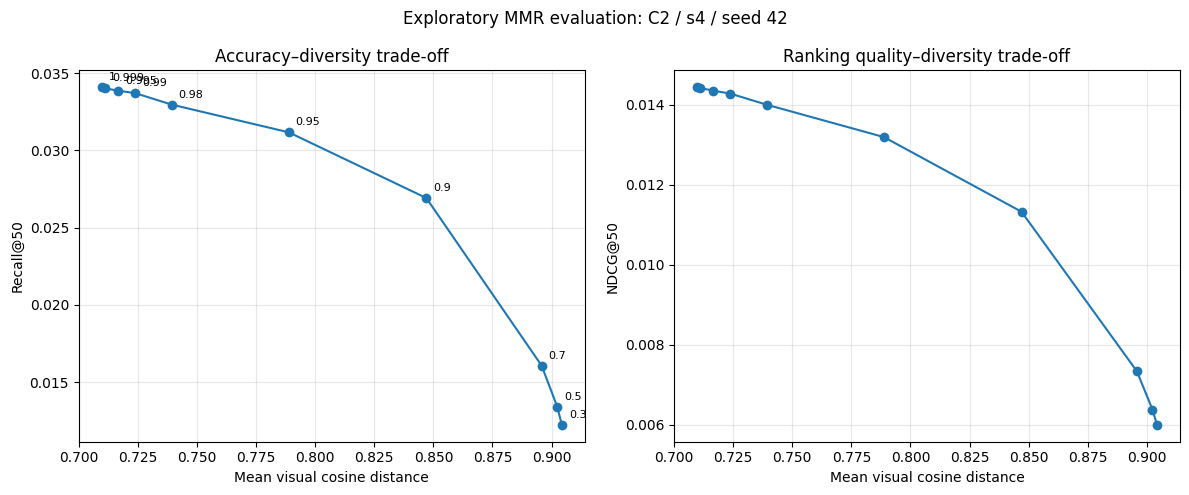

                   condition  recall_at_50  ndcg_at_50  visual_diversity
                lambda_1p000      0.034098    0.014443          0.709668
                lambda_0p999      0.034028    0.014424          0.711037
                lambda_0p995      0.033871    0.014357          0.716570
                lambda_0p990      0.033714    0.014283          0.723820
                lambda_0p980      0.032973    0.014006          0.739241
                lambda_0p950      0.031176    0.013197          0.788796
                lambda_0p900      0.026919    0.011330          0.847009
                lambda_0p700      0.016059    0.007345          0.895807
                lambda_0p500      0.013394    0.006386          0.902419
                lambda_0p300      0.012225    0.006003          0.904342
score_only_float16_reference      0.034095    0.014446          0.709663

Saved updated CSV and graphs to: /content/drive/MyDrive/kwangsuk_mmr_onnx/20261019T055148136576Z/mmr


In [10]:
# @title 8. NDCG@50 and MMR result graph

import matplotlib.pyplot as plt

# NDCG uses distinct relevant products per customer.
ndcg_targets = targets[
    ["user", "item_idx"]
].drop_duplicates()

ndcg_rows = row_lookup.reindex(
    ndcg_targets["user"].to_numpy()
).to_numpy()

assert not pd.isna(ndcg_rows).any()
ndcg_rows = ndcg_rows.astype(np.int64)
ndcg_items = ndcg_targets["item_idx"].to_numpy()

relevant_counts = np.bincount(
    ndcg_rows, minlength=len(users)
)
has_targets = relevant_counts > 0

discounts = 1.0 / np.log2(
    np.arange(1, TOP_K + 1) + 1.0
)
ideal_lookup = np.concatenate([
    [0.0], np.cumsum(discounts)
])
ideal_dcg = ideal_lookup[
    np.minimum(relevant_counts, TOP_K)
]

def ndcg_at_50(recommendations):
    dcg = np.zeros(len(users), dtype=np.float64)

    for start in range(0, len(ndcg_targets), 10000):
        stop = min(start + 10000, len(ndcg_targets))
        rows = ndcg_rows[start:stop]

        matches = (
            recommendations[rows]
            == ndcg_items[start:stop, None]
        )
        gains = matches @ discounts

        dcg += np.bincount(
            rows, weights=gains, minlength=len(users)
        )

    return float(
        np.mean(dcg[has_targets] / ideal_dcg[has_targets])
    )

mmr_results = pd.read_csv(
    result_dir / "full_results.csv"
)

ndcg_scores = {}

for name in mmr_results["condition"]:
    recommendations = np.load(
        result_dir / f"{name}_recommendations.npy",
        allow_pickle=False
    )
    ndcg_scores[name] = ndcg_at_50(recommendations)

mmr_results["ndcg_at_50"] = (
    mmr_results["condition"].map(ndcg_scores)
)

mmr_results.to_csv(
    result_dir / "full_results.csv", index=False
)

# Plot only the lambda grid; keep the rounding reference in the CSV.
grid = mmr_results[
    mmr_results["condition"].str.startswith("lambda_")
].sort_values("lambda", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    grid["visual_diversity"],
    grid["recall_at_50"],
    "o-"
)
axes[0].set_xlabel("Mean visual cosine distance")
axes[0].set_ylabel("Recall@50")
axes[0].set_title("Accuracy–diversity trade-off")

for row in grid.itertuples(index=False):
    axes[0].annotate(
        f"{row.lambda_ if hasattr(row, 'lambda_') else ''}",
        (row.visual_diversity, row.recall_at_50)
    )

# Replace annotations with explicit lambda labels.
for annotation in list(axes[0].texts):
    annotation.remove()

for _, row in grid.iterrows():
    axes[0].annotate(
        f"{row['lambda']:g}",
        (row["visual_diversity"], row["recall_at_50"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

axes[1].plot(
    grid["visual_diversity"],
    grid["ndcg_at_50"],
    "o-"
)
axes[1].set_xlabel("Mean visual cosine distance")
axes[1].set_ylabel("NDCG@50")
axes[1].set_title("Ranking quality–diversity trade-off")

for ax in axes:
    ax.grid(alpha=0.3)

fig.suptitle(
    "Exploratory MMR evaluation: C2 / s4 / seed 42"
)
fig.tight_layout()

fig.savefig(
    result_dir / "mmr_tradeoff.png",
    dpi=200, bbox_inches="tight"
)
fig.savefig(
    result_dir / "mmr_tradeoff.pdf",
    bbox_inches="tight"
)
plt.show()

print(mmr_results[
    [
        "condition", "recall_at_50",
        "ndcg_at_50", "visual_diversity"
    ]
].to_string(index=False))

print("\nSaved updated CSV and graphs to:", result_dir)

In [11]:
# @title 9. Install ONNX tools
%pip -q install onnx onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 33.7 MB/s eta 0:00:00


In [12]:
# @title 10. Export normalized towers and verify outputs

import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import onnx
import onnxruntime as ort

from msrs_paper import two_tower

model_dir = paths.run_dir(
    "YH5_EXPORT", "s4", "C2_seed42"
)

model, X, Uin, loaded_users = two_tower.load_trained(
    paths, model_dir, device="cpu"
)
model.eval()

X = np.ascontiguousarray(X, dtype=np.float32)
Uin = np.ascontiguousarray(Uin, dtype=np.float32)

saved_users = np.load(
    model_dir / "users.npy", allow_pickle=False
)
assert np.array_equal(loaded_users, saved_users)
assert np.isfinite(X).all()
assert np.isfinite(Uin).all()

class NormalizedTower(nn.Module):
    def __init__(self, tower):
        super().__init__()
        self.tower = tower

    def forward(self, x):
        return F.normalize(
            self.tower(x), p=2, dim=1, eps=1e-12
        )

item_tower = NormalizedTower(model.item).cpu().eval()
user_tower = NormalizedTower(model.user).cpu().eval()

export_stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S%fZ"
)

onnx_dir = Path(
    "/content/drive/MyDrive/kwangsuk_mmr_onnx/"
    "20261019T055148136576Z/onnx"
) / export_stamp

onnx_dir.mkdir(parents=True, exist_ok=False)

towers = {
    "item": (item_tower, X),
    "user": (user_tower, Uin),
}

sessions = {}
checks = []
rng = np.random.default_rng(42)

for name, (tower, inputs) in towers.items():
    file = onnx_dir / f"{name}_tower.onnx"

    print(f"Exporting {name} tower...", flush=True)

    torch.onnx.export(
        tower,
        torch.from_numpy(inputs[:4]),
        str(file),
        input_names=["input"],
        output_names=["embedding"],
        dynamic_axes={
            "input": {0: "batch"},
            "embedding": {0: "batch"},
        },
        opset_version=17,
        dynamo=False,
    )

    onnx.checker.check_model(onnx.load(str(file)))

    options = ort.SessionOptions()
    options.intra_op_num_threads = 1
    options.inter_op_num_threads = 1

    session = ort.InferenceSession(
        str(file),
        sess_options=options,
        providers=["CPUExecutionProvider"],
    )
    sessions[name] = session

    # Check different batch sizes using real inputs.
    for batch_size in [1, 4, 32, 256]:
        indices = rng.choice(
            len(inputs), size=batch_size, replace=False
        )
        sample = np.ascontiguousarray(inputs[indices])

        with torch.inference_mode():
            pytorch_output = tower(
                torch.from_numpy(sample)
            ).numpy()

        onnx_output = session.run(
            ["embedding"], {"input": sample}
        )[0]

        assert np.isfinite(pytorch_output).all()
        assert np.isfinite(onnx_output).all()

        error = np.abs(pytorch_output - onnx_output)
        passed = np.allclose(
            pytorch_output,
            onnx_output,
            atol=1e-5,
            rtol=1e-4,
        )

        checks.append({
            "tower": name,
            "batch_size": batch_size,
            "max_absolute_error": float(error.max()),
            "mean_absolute_error": float(error.mean()),
            "passed": bool(passed),
        })

    print(f"Saved: {file}", flush=True)

check_table = pd.DataFrame(checks)
check_table.to_csv(
    onnx_dir / "output_checks.csv", index=False
)

with open(
    onnx_dir / "export_settings.json",
    "w", encoding="utf-8"
) as f:
    json.dump({
        "source_model": str(model_dir),
        "condition": "C2",
        "split": "s4",
        "seed": 42,
        "opset": 17,
        "normalization_included": True,
        "provider": "CPUExecutionProvider",
        "atol": 1e-5,
        "rtol": 1e-4,
        "torch_version": torch.__version__,
        "onnx_version": onnx.__version__,
        "onnxruntime_version": ort.__version__,
    }, f, indent=2)

print("\nOutput comparison:")
print(check_table.to_string(index=False))

assert check_table["passed"].all(), (
    "Some output checks failed. Stop before benchmarking."
)

print("\nAll sampled output checks passed.")
print("Saved to:", onnx_dir)

Exporting item tower...


/tmp/ipykernel_1205/2488453768.py:74: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


Saved: /content/drive/MyDrive/kwangsuk_mmr_onnx/20261019T055148136576Z/onnx/20261019T055939355814Z/item_tower.onnx
Exporting user tower...
Saved: /content/drive/MyDrive/kwangsuk_mmr_onnx/20261019T055148136576Z/onnx/20261019T055939355814Z/user_tower.onnx

Output comparison:
tower  batch_size  max_absolute_error  mean_absolute_error  passed
 item           1        5.960464e-08         1.780973e-08    True
 item           4        7.450581e-08         1.818066e-08    True
 item          32        5.960464e-08         5.116807e-09    True
 item         256        7.450581e-08         4.990937e-09    True
 user           1        8.195639e-08         2.515026e-08    True
 user           4        1.192093e-07         2.838703e-08    True
 user          32        5.960464e-08         3.577278e-09    True
 user         256        5.960464e-08         4.310602e-09    True

All sampled output checks passed.
Saved to: /content/drive/MyDrive/kwangsuk_mmr_onnx/20261019T055148136576Z/onnx/20261019T

In [13]:
# @title 11. Compare PyTorch and ONNX recommendations

torch.set_num_threads(1)

CHECK_CUSTOMERS = min(1000, len(loaded_users))
CHECK_BATCH = 32
ITEM_BATCH = 2048

rng = np.random.default_rng(42)
check_rows = np.sort(
    rng.choice(
        len(loaded_users),
        size=CHECK_CUSTOMERS,
        replace=False
    )
)
check_users = loaded_users[check_rows]

# Compute full-catalogue item vectors in manageable batches.
def encode_pytorch(tower, inputs, batch_size):
    batches = []
    with torch.inference_mode():
        for start in range(0, len(inputs), batch_size):
            sample = np.ascontiguousarray(
                inputs[start:start + batch_size]
            )
            batches.append(
                tower(torch.from_numpy(sample)).numpy()
            )
    return np.concatenate(batches)

def encode_onnx(session, inputs, batch_size):
    batches = []
    for start in range(0, len(inputs), batch_size):
        sample = np.ascontiguousarray(
            inputs[start:start + batch_size]
        )
        batches.append(
            session.run(
                ["embedding"], {"input": sample}
            )[0]
        )
    return np.concatenate(batches)

print("Encoding catalogue...", flush=True)

pt_items = encode_pytorch(item_tower, X, ITEM_BATCH)
ort_items = encode_onnx(sessions["item"], X, ITEM_BATCH)

sample_inputs = np.ascontiguousarray(Uin[check_rows])
pt_users = encode_pytorch(
    user_tower, sample_inputs, CHECK_BATCH
)
ort_users = encode_onnx(
    sessions["user"], sample_inputs, CHECK_BATCH
)

# Both implementations use the same ranking operation.
def top_k(scores, k):
    return torch.topk(
        torch.from_numpy(np.ascontiguousarray(scores)),
        k=k, dim=1
    ).indices.numpy()

pt_lists = []
ort_lists = []
max_score_error = 0.0

print("Comparing recommendations...", flush=True)

for start in range(0, CHECK_CUSTOMERS, CHECK_BATCH):
    stop = min(start + CHECK_BATCH, CHECK_CUSTOMERS)

    pt_scores = pt_users[start:stop] @ pt_items.T
    ort_scores = ort_users[start:stop] @ ort_items.T

    max_score_error = max(
        max_score_error,
        float(np.max(np.abs(pt_scores - ort_scores)))
    )

    pt_lists.append(top_k(pt_scores, 300))
    ort_lists.append(top_k(ort_scores, 300))

pt_recommendations = np.concatenate(pt_lists)
ort_recommendations = np.concatenate(ort_lists)

check_targets = targets[
    targets["user"].isin(check_users)
].copy()

comparison_rows = []

for k in [50, 300]:
    pt_top = pt_recommendations[:, :k]
    ort_top = ort_recommendations[:, :k]

    overlap = np.mean([
        len(np.intersect1d(a, b)) / k
        for a, b in zip(pt_top, ort_top)
    ])

    exact_order = np.mean(
        np.all(pt_top == ort_top, axis=1)
    )

    pt_recall = metrics.recall_user_mean(
        pt_top, check_users, check_targets, k
    )
    ort_recall = metrics.recall_user_mean(
        ort_top, check_users, check_targets, k
    )

    comparison_rows.append({
        "k": k,
        "customers": CHECK_CUSTOMERS,
        "mean_set_overlap": overlap,
        "exact_order_customer_fraction": exact_order,
        "pytorch_recall": pt_recall,
        "onnx_recall": ort_recall,
        "recall_difference": ort_recall - pt_recall,
    })

recommendation_check = pd.DataFrame(comparison_rows)

recommendation_check.to_csv(
    onnx_dir / "recommendation_checks.csv", index=False
)

np.save(onnx_dir / "check_users.npy", check_users)
np.save(
    onnx_dir / "pytorch_check_recommendations.npy",
    pt_recommendations.astype(np.int32)
)
np.save(
    onnx_dir / "onnx_check_recommendations.npy",
    ort_recommendations.astype(np.int32)
)

with open(
    onnx_dir / "recommendation_check_settings.json",
    "w", encoding="utf-8"
) as f:
    json.dump({
        "sample_seed": 42,
        "customers": CHECK_CUSTOMERS,
        "catalogue_products": len(X),
        "max_absolute_score_error": max_score_error,
        "comparison": "PyTorch FP32 vs ONNX FP32",
        "item_vectors_recomputed": True,
        "includes_mmr": False,
    }, f, indent=2)

print("\nRecommendation comparison:")
print(recommendation_check.to_string(index=False))
print("\nMaximum score difference:", max_score_error)
print("Saved to:", onnx_dir)

Encoding catalogue...
Comparing recommendations...

Recommendation comparison:
  k  customers  mean_set_overlap  exact_order_customer_fraction  pytorch_recall  onnx_recall  recall_difference
 50       1000               1.0                          0.994        0.038148     0.038148                0.0
300       1000               1.0                          0.908        0.103181     0.103181                0.0

Maximum score difference: 5.364418029785156e-07
Saved to: /content/drive/MyDrive/kwangsuk_mmr_onnx/20261019T055148136576Z/onnx/20261019T055939355814Z


In [14]:
# @title 12. CPU latency comparison — PyTorch vs ONNX

import os
import platform
import time
from threadpoolctl import threadpool_limits, threadpool_info

WARMUP = 20
REQUESTS_PER_ROUND = 500
ROUNDS = 3
BENCHMARK_SEED = 42

torch.set_num_threads(1)
user_tower.cpu().eval()

# Create a CPU session with explicit settings.
bench_options = ort.SessionOptions()
bench_options.intra_op_num_threads = 1
bench_options.inter_op_num_threads = 1
bench_options.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
bench_options.graph_optimization_level = (
    ort.GraphOptimizationLevel.ORT_ENABLE_ALL
)

bench_session = ort.InferenceSession(
    str(onnx_dir / "user_tower.onnx"),
    sess_options=bench_options,
    providers=["CPUExecutionProvider"],
)

# Identical cached product vectors for both retrieval paths.
# Product encoding is an offline operation, excluded from request timing.
cached_items = np.ascontiguousarray(
    pt_items, dtype=np.float32
)

# Reuse the real customer inputs from the correctness check.
request_inputs = [
    np.ascontiguousarray(sample_inputs[i:i + 1])
    for i in range(len(sample_inputs))
]

def pytorch_user(x):
    return user_tower(torch.from_numpy(x)).numpy()

def onnx_user(x):
    return bench_session.run(
        ["embedding"], {"input": x}
    )[0]

def retrieve(encode, x):
    embedding = encode(x)
    scores = embedding @ cached_items.T

    # Same scoring and selection implementation for both backends.
    return torch.topk(
        torch.from_numpy(np.ascontiguousarray(scores)),
        k=300, dim=1
    ).indices.numpy()

operations = {
    "user_tower_only": {
        "pytorch": pytorch_user,
        "onnx": onnx_user,
    },
    "user_tower_scores_top300": {
        "pytorch": lambda x: retrieve(pytorch_user, x),
        "onnx": lambda x: retrieve(onnx_user, x),
    },
}

rng = np.random.default_rng(BENCHMARK_SEED)
timings = []

# Limit NumPy/BLAS threads too, not only model threads.
with threadpool_limits(limits=1), torch.inference_mode():
    pools = threadpool_info()

    for scope, backends in operations.items():
        print(f"\nBenchmarking: {scope}", flush=True)

        for operation in backends.values():
            for i in range(WARMUP):
                operation(request_inputs[i % len(request_inputs)])

        for round_id in range(ROUNDS):
            input_ids = rng.integers(
                0, len(request_inputs),
                size=REQUESTS_PER_ROUND
            )

            for request_id, input_id in enumerate(input_ids):
                x = request_inputs[input_id]

                # Alternate backend order to reduce order effects.
                names = (
                    ["pytorch", "onnx"]
                    if (request_id + round_id) % 2 == 0
                    else ["onnx", "pytorch"]
                )

                for backend in names:
                    started = time.perf_counter_ns()
                    output = backends[backend](x)
                    elapsed_ms = (
                        time.perf_counter_ns() - started
                    ) / 1e6

                    timings.append({
                        "scope": scope,
                        "backend": backend,
                        "round": round_id + 1,
                        "request": request_id,
                        "input_sample": int(input_id),
                        "latency_ms": elapsed_ms,
                    })

            print(
                f"Round {round_id + 1}/{ROUNDS} completed",
                flush=True
            )

raw_timings = pd.DataFrame(timings)

latency_summary = (
    raw_timings.groupby(["scope", "backend"])["latency_ms"]
    .agg(
        measurements="count",
        median_ms="median",
        p95_ms=lambda x: x.quantile(0.95),
        mean_ms="mean",
    )
    .reset_index()
)

# Save individual measurements and per-round summaries.
raw_timings.to_csv(
    onnx_dir / "latency_raw.csv", index=False
)
latency_summary.to_csv(
    onnx_dir / "latency_summary.csv", index=False
)

round_summary = (
    raw_timings.groupby(
        ["scope", "backend", "round"]
    )["latency_ms"]
    .agg(
        median_ms="median",
        p95_ms=lambda x: x.quantile(0.95),
    )
    .reset_index()
)
round_summary.to_csv(
    onnx_dir / "latency_by_round.csv", index=False
)

# Compare equivalent tower weights, excluding optimizer state.
size_rows = []
for name, tower in [
    ("user", user_tower),
    ("item", item_tower)
]:
    pt_file = onnx_dir / f"{name}_tower_weights.pt"
    torch.save(tower.state_dict(), pt_file)

    size_rows.append({
        "tower": name,
        "pytorch_weights_bytes": pt_file.stat().st_size,
        "onnx_bytes": (
            onnx_dir / f"{name}_tower.onnx"
        ).stat().st_size,
    })

size_table = pd.DataFrame(size_rows)
size_table.to_csv(
    onnx_dir / "model_sizes.csv", index=False
)

with open(
    onnx_dir / "benchmark_settings.json",
    "w", encoding="utf-8"
) as f:
    json.dump({
        "seed": BENCHMARK_SEED,
        "warmup_per_scope_backend": WARMUP,
        "requests_per_round": REQUESTS_PER_ROUND,
        "rounds": ROUNDS,
        "request_batch_size": 1,
        "computational_threads": 1,
        "catalogue_products": len(cached_items),
        "cached_item_vectors": "shared PyTorch FP32 vectors",
        "platform": platform.platform(),
        "logical_cpu_count": os.cpu_count(),
        "torch_version": torch.__version__,
        "onnxruntime_version": ort.__version__,
        "threadpools_during_measurement": pools,
        "excluded": [
            "model loading",
            "file and database access",
            "history averaging",
            "text/image encoding",
            "item-tower precomputation",
            "MMR",
            "HTTP/API handling",
        ],
    }, f, indent=2, default=str)

print("\nCPU latency results:")
print(latency_summary.to_string(index=False))

print("\nModel file sizes:")
print(size_table.to_string(index=False))

print("\nSaved to:", onnx_dir)


Benchmarking: user_tower_only
Round 1/3 completed
Round 2/3 completed
Round 3/3 completed

Benchmarking: user_tower_scores_top300
Round 1/3 completed
Round 2/3 completed
Round 3/3 completed

CPU latency results:
                   scope backend  measurements  median_ms    p95_ms  mean_ms
         user_tower_only    onnx          1500   0.125833  0.180367 0.192814
         user_tower_only pytorch          1500   0.300869  1.411889 0.433645
user_tower_scores_top300    onnx          1500   2.828390  9.747339 4.015074
user_tower_scores_top300 pytorch          1500   3.039797 10.439685 4.278914

Model file sizes:
tower  pytorch_weights_bytes  onnx_bytes
 user                1315979     1314365
 item                1315979     1314365

Saved to: /content/drive/MyDrive/kwangsuk_mmr_onnx/20261019T055148136576Z/onnx/20261019T055939355814Z


In [15]:
# @title 13. Save experiment summary

summary_file = onnx_dir.parent.parent / "EXPERIMENT_SUMMARY.md"

summary_text = """# MMR and ONNX exploratory experiments

## Baseline
- Condition: C2, text + Marqo image features
- Split: s4
- Training seed: 42
- Catalogue: 53,232 products
- Evaluation customers: 49,061

## MMR
MMR reranked a fixed pool of 300 candidates into 50 recommendations.
Relevance used saved model-vector cosine scores.
Redundancy used Marqo image-embedding cosine similarity.

Visual diversity increased as diversification strengthened, while
Recall@50 and NDCG@50 decreased.

At lambda=0.999:
- Recall@50 difference: approximately -0.000070
- Pointwise 95% customer-bootstrap interval: [-0.000166, 0.000012]
- Visual diversity difference: approximately +0.001369

An interval containing zero does not establish unchanged accuracy.
The lambda grid was expanded after inspecting test-set pilot results;
all comparisons are exploratory.

## ONNX correctness
On 1,000 fixed sampled customers:
- Top-50 and Top-300 recommendation sets matched between implementations.
- Recall@50 and Recall@300 were identical.
- Some within-list ordering differed near numerical ties.
- Maximum observed score difference: approximately 5.36e-7.

## ONNX CPU latency
Single-request measurements, one computational thread:
20 warm-up calls per scope/backend, followed by
3 rounds of 500 measurements per backend and scope.

| Scope | PyTorch median | ONNX median | PyTorch p95 | ONNX p95 |
|---|---:|---:|---:|---:|
| User tower | 0.300869 ms | 0.125833 ms | 1.411889 ms | 0.180367 ms |
| User tower + scoring + Top-300 | 3.039797 ms | 2.828390 ms | 10.439685 ms | 9.747339 ms |

User-tower median latency decreased by approximately 58.2%.
Retrieval-component median latency decreased by approximately 7.0%.

## File sizes
Per tower:
- PyTorch weights: 1,315,979 bytes
- ONNX: 1,314,365 bytes

The approximately 0.12% difference is not substantial compression.
No quantization was applied.

## Limitations
- One trained condition, split and seed.
- Bootstrap intervals are pointwise and conditional on the fixed model.
- Visual diversity uses the same representation targeted by MMR.
- Visual diversity is not a direct measure of user satisfaction.
- ONNX recommendation agreement was checked on a 1,000-customer sample.
- Latency was measured on the Colab CPU, not the deployment computer.
- Item vectors were cached for retrieval.
- Timing excludes history averaging, database access, HTTP handling,
  text/image encoding and MMR.
- Full API latency below 100 ms has not been established.

## Saved results
- MMR tables, recommendations, bootstrap intervals and figures: mmr/
- ONNX models, correctness checks and latency measurements: onnx/
"""

summary_file.write_text(summary_text, encoding="utf-8")
print("Summary saved to:", summary_file)

Summary saved to: /content/drive/MyDrive/kwangsuk_mmr_onnx/20261019T055148136576Z/EXPERIMENT_SUMMARY.md


In [16]:
# @title 14. Download results for GitHub

from pathlib import Path
import hashlib
import json
import zipfile
from google.colab import files

source = Path(
    "/content/drive/MyDrive/kwangsuk_mmr_onnx/"
    "20261019T055148136576Z"
)
assert source.is_dir(), f"Folder not found: {source}"

archive = Path(
    "/content/kwangsuk_mmr_onnx_results_20261019.zip"
)

allowed_extensions = {".md", ".csv", ".json", ".png", ".pdf"}

selected = sorted(
    p for p in source.rglob("*")
    if p.is_file() and (
        p.suffix.lower() in allowed_extensions
        or p.name == "paired_bootstrap_estimates.npy"
    )
)

assert (source / "EXPERIMENT_SUMMARY.md") in selected
assert selected, "No result files found."

manifest = {
    "source_folder": str(source),
    "files": [
        {
            "path": str(p.relative_to(source)),
            "bytes": p.stat().st_size,
            "sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
        }
        for p in selected
    ],
    "excluded": (
        "Model weights, ONNX binaries, customer IDs and "
        "per-customer recommendation arrays remain on Drive."
    ),
}

with zipfile.ZipFile(
    archive, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for p in selected:
        z.write(p, str(p.relative_to(source)))

    z.writestr(
        "PACKAGE_MANIFEST.json",
        json.dumps(manifest, ensure_ascii=False, indent=2)
    )

print("Packaged files:", len(selected))
print("ZIP size:", round(archive.stat().st_size / 1024, 1), "KB")
files.download(str(archive))

Packaged files: 18
ZIP size: 349.5 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>